In [1]:
import pandas as pd

import numpy as np

from collections import OrderedDict

import matplotlib.pyplot as plt

import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

import scipy.stats as sci

from sklearn.preprocessing import LabelEncoder

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, cross_val_score,KFold,GridSearchCV , learning_curve

from sklearn.metrics import mean_squared_error , r2_score

from sklearn.linear_model import LinearRegression , Lasso , Ridge

from sklearn.tree import DecisionTreeRegressor 

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.ensemble import RandomForestRegressor , AdaBoostRegressor,GradientBoostingRegressor

import xgboost 

from xgboost import XGBRegressor

In [2]:
df1 = pd.read_excel("Medibuddy insurance data personal details copy_raw.xlsx")
df2 = pd.read_excel("Medibuddy Insurance Data Price _raw.xlsx")

In [3]:
print(df1.shape)
print(df2.shape)

(1338, 4)
(1338, 5)


In [4]:
df1.head(2)

,Policy no.,children,smoker,region
0,PLC157006,0,no,southwest
1,PLC157033,1,no,southwest


In [5]:
df2.head(2)

,Policy no.,age,sex,bmi,charges in INR
0,PLC156898,19,female,27.90,16884.9240
1,PLC156907,18,male,33.77,1725.5523


In [6]:
df = df1.merge(df2,how = "inner",on = "Policy no.")

In [7]:
df_bkp = df

In [8]:
df.head()

,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
0,PLC157006,0,no,southwest,23,male,34.4,1826.843
1,PLC157033,1,no,southwest,19,male,24.6,1837.237
2,PLC157060,0,no,southwest,56,male,40.3,10602.385
3,PLC157087,1,no,southwest,30,female,32.4,4149.736
4,PLC157186,5,no,southwest,19,female,28.6,4687.797


In [9]:
df.dropna()

,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
0,PLC157006,0,no,southwest,23,male,34.400,1826.84300
1,PLC157033,1,no,southwest,19,male,24.600,1837.23700
2,PLC157060,0,no,southwest,56,male,40.300,10602.38500
3,PLC157087,1,no,southwest,30,female,32.400,4149.73600
4,PLC157186,5,no,southwest,19,female,28.600,4687.79700
...,...,...,...,...,...,...,...,...
1333,PLC168400,1,yes,northeast,39,male,29.925,22462.04375
1334,PLC168436,0,yes,northeast,18,female,21.660,14283.45940
1335,PLC168634,2,yes,northeast,42,male,24.605,21259.37795
1336,PLC168652,0,yes,northeast,29,female,21.850,16115.30450


In [10]:
df.drop_duplicates()

,Policy no.,children,smoker,region,age,sex,bmi,charges in INR
0,PLC157006,0,no,southwest,23,male,34.400,1826.84300
1,PLC157033,1,no,southwest,19,male,24.600,1837.23700
2,PLC157060,0,no,southwest,56,male,40.300,10602.38500
3,PLC157087,1,no,southwest,30,female,32.400,4149.73600
4,PLC157186,5,no,southwest,19,female,28.600,4687.79700
...,...,...,...,...,...,...,...,...
1333,PLC168400,1,yes,northeast,39,male,29.925,22462.04375
1334,PLC168436,0,yes,northeast,18,female,21.660,14283.45940
1335,PLC168634,2,yes,northeast,42,male,24.605,21259.37795
1336,PLC168652,0,yes,northeast,29,female,21.850,16115.30450


In [11]:
df.drop("Policy no.",axis  = 1 ,inplace=True)

### Custom Summary

In [12]:
def custom_summary(data):
    result = []
    
    for col in data.columns:
        if data[col].dtype != 'O':
            
            stats = OrderedDict({
                "Feature Name":col,
                "Count":data[col].count(),
                "Minimum":data[col].min(),
                "First Quartile":data[col].quantile(0.25),
                "Mean":data[col].mean(),
                "Median":data[col].median(),
                "Third Quartile":data[col].quantile(0.75),
                "Variance":data[col].var(),
                "Standard Deviation":data[col].std(),
                "Kurtosis":data[col].kurt(),
                "Skewness":data[col].skew(),
                "IQR" : data[col].quantile(0.75) - data[col].quantile(0.25)

            })
            
            result.append(stats)
            
    result_df = pd.DataFrame(result)
    
    
    skewtype = []
    
    for i in result_df["Skewness"]:
        
        if i <= -1:
            skewtype.append("Highly Negatively Skewed")
        elif i <= -0.5:
            skewtype.append("Moderately Negatively Skewed")
        elif -0.5 < i < 0:
            skewtype.append("Approx Normal Distribution(-ve)")
        elif 0 <= i < 0.5:
            skewtype.append("Approx Normal Distribution(+ve)")
        elif 0.5 <= i < 1:
            skewtype.append("Moderately Positively Skewed")
        elif i >= 1:
            skewtype.append("Highly Positively Skewed")
            
    result_df["Skew_Type"] = skewtype
    
    
    k_type = []
    
    for i in result_df["Kurtosis"]:
        
        if i <= -1:
            k_type.append("Highly Platykurtic Curve")
        elif -1 < i <= -0.5:
            k_type.append("Moderately Platykurtic Curve")
        elif -0.5 < i <= 0.5:
            k_type.append("Mesokurtic Curve")
        elif 0.5 < i <= 1:
            k_type.append("Moderately Leptokurtic Curve")
        elif i > 1:
            k_type.append("Highly Leptokurtic  Curve")
            
    result_df["Kurtosis_Type"] = k_type
    
# Outlier Detection

    up_limit = stats["Third Quartile"] + 1.5 * stats["IQR"]

    low_limit = stats["First Quartile"] - 1.5 * stats["IQR"]
    
    if len([x for x in data[col] if x < low_limit or x > up_limit]) > 0 :
        outlier_comment = "Has outliers"
        outlier_percentage = len([x for x in data[col] if x < low_limit or x > up_limit]) / len(data)
    else:
        outlier_comment = "No outliers"
        outlier_percentage = 0
        
    result_df['Outlier_Comment']= outlier_comment
    
    result_df['Outlier_Percentage'] = outlier_percentage

    
    return result_df

In [13]:
custom_summary(df)

,Feature Name,Count,Minimum,First Quartile,Mean,Median,Third Quartile,Variance,Standard Deviation,Kurtosis,Skewness,IQR,Skew_Type,Kurtosis_Type,Outlier_Comment,Outlier_Percentage
0,children,1338,0.0000,0.00000,1.094918,1.000,2.000000,1.453213e+00,1.205493,0.202454,0.938380,2.000000,Moderately Positively Skewed,Mesokurtic Curve,Has outliers,0.103886
1,age,1338,18.0000,27.00000,39.207025,39.000,51.000000,1.974014e+02,14.049960,-1.245088,0.055673,24.000000,Approx Normal Distribution(+ve),Highly Platykurtic Curve,Has outliers,0.103886
2,bmi,1338,15.9600,26.29625,30.663397,30.400,34.693750,3.718788e+01,6.098187,-0.050732,0.284047,8.397500,Approx Normal Distribution(+ve),Mesokurtic Curve,Has outliers,0.103886
3,charges in INR,1338,1121.8739,4740.28715,13270.422265,9382.033,16639.912515,1.466524e+08,12110.011237,1.606299,1.515880,11899.625365,Highly Positively Skewed,Highly Leptokurtic Curve,Has outliers,0.103886


### Outlier Treatment

In [14]:
def outlier_treatment(data,col):
    
    col_data = data[col]
    
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
        
    iqr = q3 - q1
        
    low_limit = q1 - 1.5*iqr
    up_limit = q3 + 1.5*iqr
    
    
    outliers = data.loc[(col_data < low_limit) | (col_data > up_limit) , col] 
    
    outlier_density = outliers / len(data)
    
    if len(outliers) == 0:
        
        print(f"column {col} does not have any outliers")
    
    else :
        
        print(f"column {col} has outliers and they are ",outliers)
        

    data.loc[(col_data < low_limit),col] = low_limit 
    data.loc[(col_data > up_limit),col] = up_limit
    
    return data


In [15]:
for col in df.columns:
    if df[col].dtype != "O":
        outlier_treatment(df,col)

column children does not have any outliers
column age does not have any outliers
column bmi has outliers and they are  287     49.06
349     47.52
449     50.38
492     47.74
535     53.13
857     48.07
1100    47.60
1157    47.41
1192    52.58
Name: bmi, dtype: float64
column charges in INR has outliers and they are  45      35160.13457
241     36910.60803
480     36580.28216
1065    36837.46700
1066    38711.00000
           ...     
1318    39047.28500
1319    41034.22140
1324    44641.19740
1326    40904.19950
1330    37607.52770
Name: charges in INR, Length: 139, dtype: float64


In [16]:
custom_summary(df)

,Feature Name,Count,Minimum,First Quartile,Mean,Median,Third Quartile,Variance,Standard Deviation,Kurtosis,Skewness,IQR,Skew_Type,Kurtosis_Type,Outlier_Comment,Outlier_Percentage
0,children,1338,0.0000,0.00000,1.094918,1.000,2.000000,1.453213e+00,1.205493,0.202454,0.938380,2.000000,Moderately Positively Skewed,Mesokurtic Curve,No outliers,0
1,age,1338,18.0000,27.00000,39.207025,39.000,51.000000,1.974014e+02,14.049960,-1.245088,0.055673,24.000000,Approx Normal Distribution(+ve),Highly Platykurtic Curve,No outliers,0
2,bmi,1338,15.9600,26.29625,30.650034,30.400,34.693750,3.668635e+01,6.056926,-0.236322,0.232507,8.397500,Approx Normal Distribution(+ve),Mesokurtic Curve,No outliers,0
3,charges in INR,1338,1121.8739,4740.28715,12479.369251,9382.033,16639.912515,1.031861e+08,10158.056096,0.018454,1.083730,11899.625365,Highly Positively Skewed,Mesokurtic Curve,No outliers,0


### Label Encoding

In [17]:
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == "O":
        df[col] = le.fit_transform(df[col])

### Regression Analysis

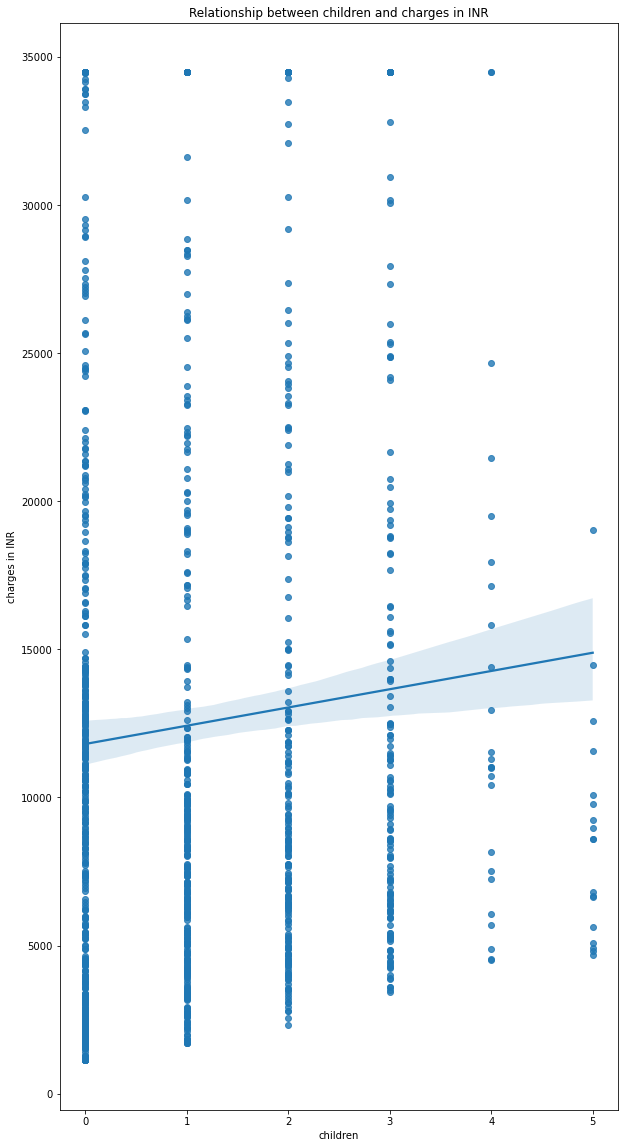

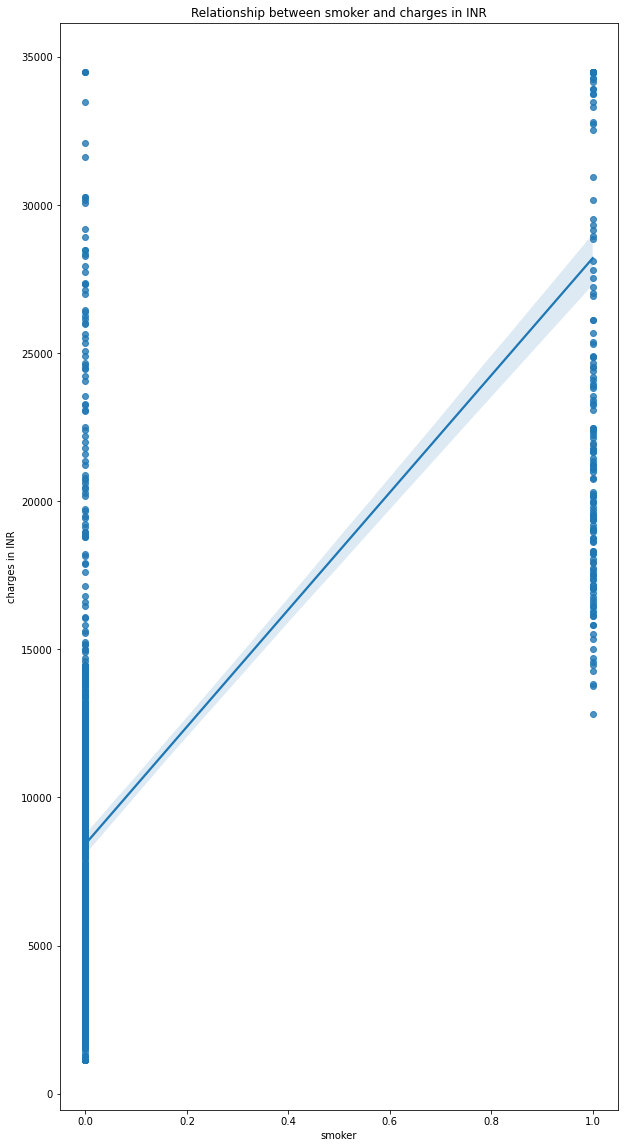

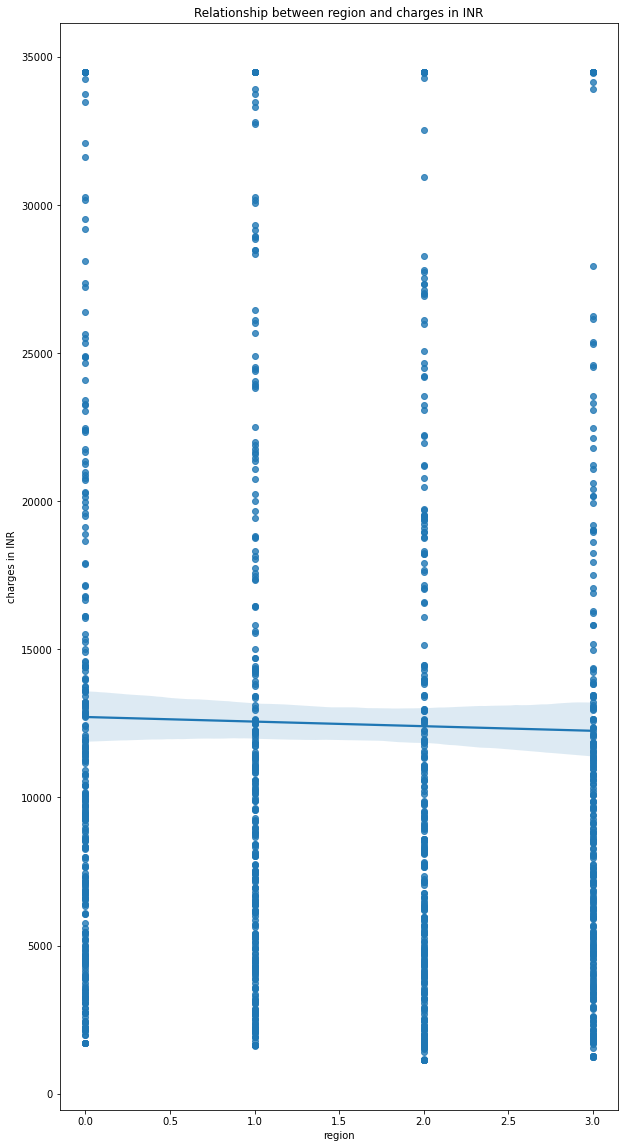

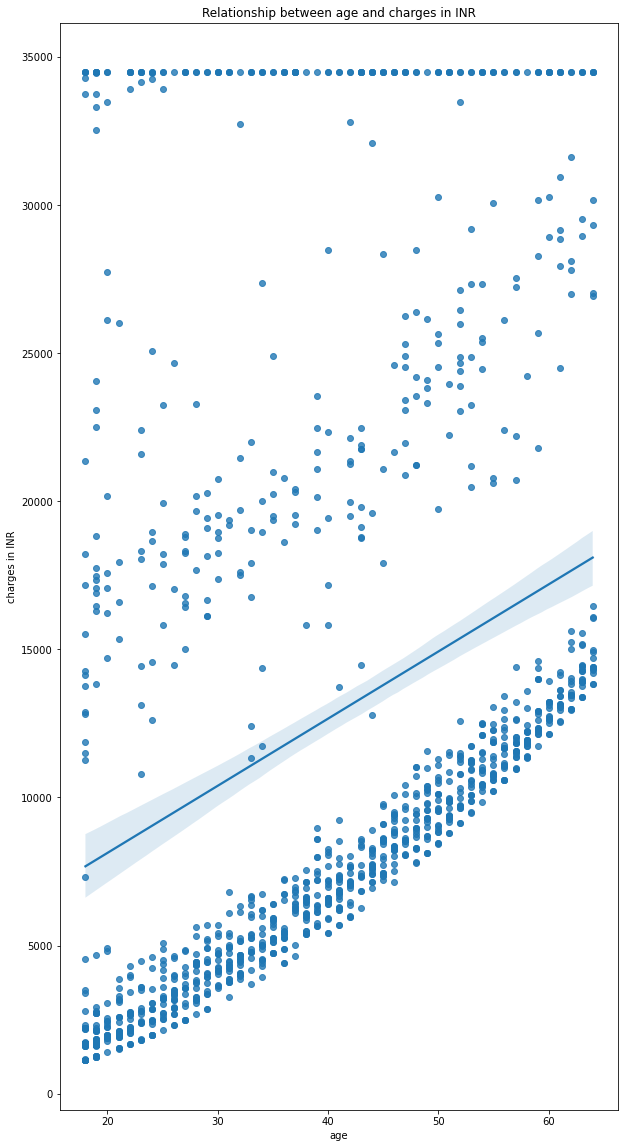

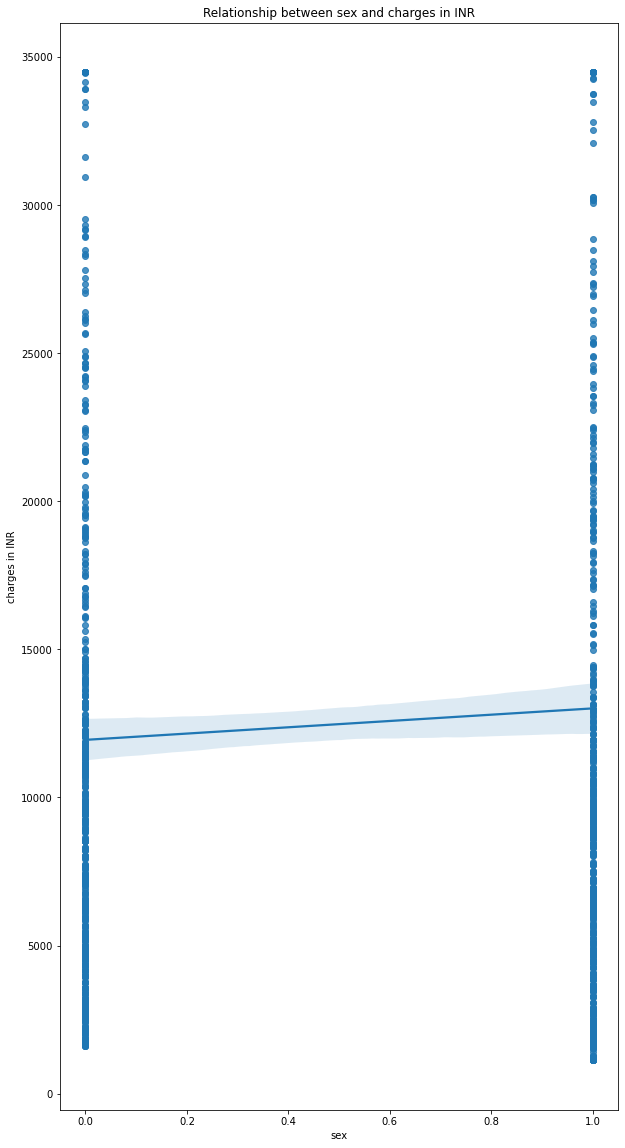

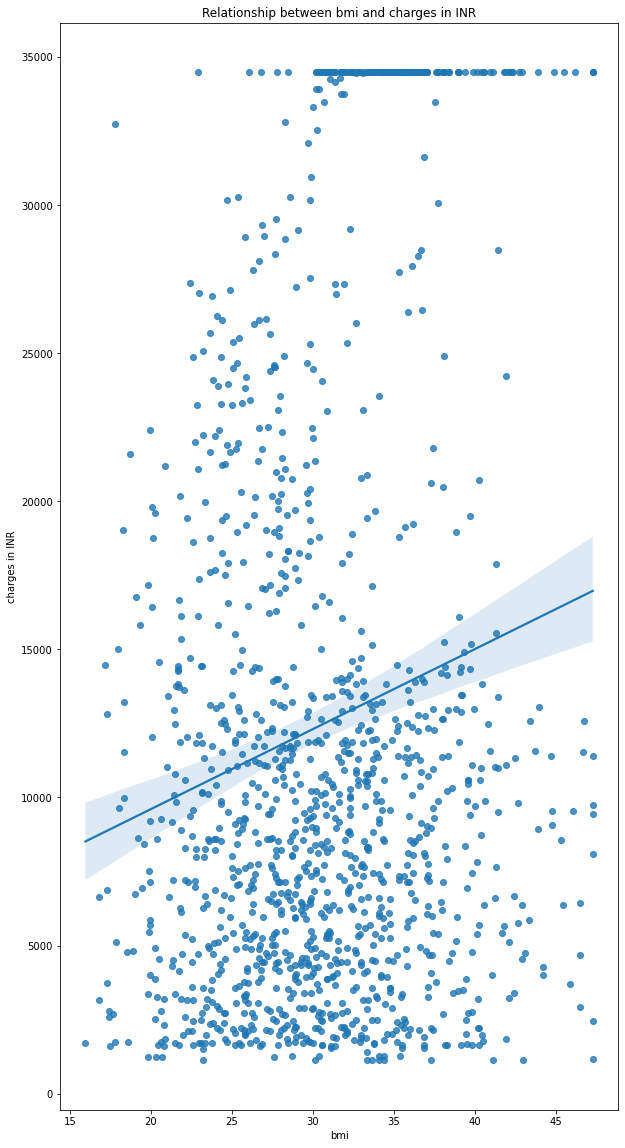

In [18]:
for col in df.columns:
    if col != "charges in INR":
        
        f,ax = plt.subplots(figsize = (10,20))
        
        sns.regplot(x = df[col] , y = df["charges in INR"]).set_title(f'Relationship between {col} and charges in INR')


In [19]:
# Correlation with the target variable

def correlation_target(data , target_col):
    data_new = data.drop([target_col] , axis =1)
    indep_cols = data_new.columns
    
    correlation_result = []
    
    for col in indep_cols:
        correlation_result.append(data[target_col].corr(data[col]))
            
    result_df = pd.DataFrame([indep_cols,correlation_result] , index=["Variable","Correlation"]).T
        
    return result_df.sort_values("Correlation" , ascending = False)

In [20]:
correlation_target(df,"charges in INR")

,Variable,Correlation
1,smoker,0.785958
3,age,0.313394
5,bmi,0.160996
0,children,0.073074
4,sex,0.052322
2,region,-0.01689


### Multicollinearity Check - Heatmap

<AxesSubplot:>

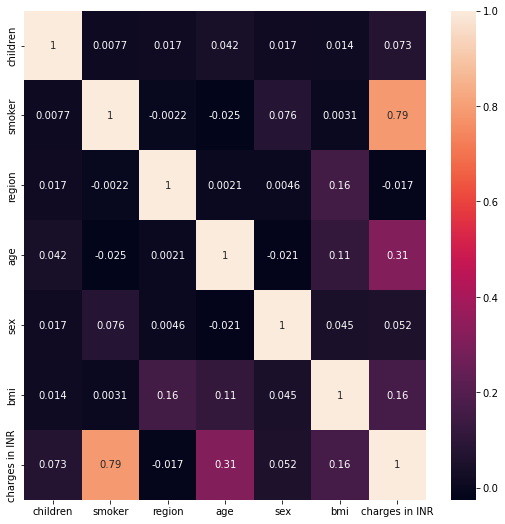

In [21]:
## To get the equations, we must check --- Multicollinearity 

corr = df.corr()
f,ax = plt.subplots(figsize =(9,9))
sns.heatmap(corr,annot = True)

# annot  = True--> displays the values

### Variance Inflation Factor

In [22]:
def vif_factor(indep_var):
    vif_df = pd.DataFrame()
    vif_df["Features"] = indep_var.columns
    vif_df["VIF"]= [variance_inflation_factor(indep_var.values,i) for i in range(indep_var.shape[1]) ]

    return vif_df.sort_values("VIF" , ascending = False)

In [23]:
vif_factor(df.drop("charges in INR" , axis  = 1))

,Features,VIF
5,bmi,10.427230
3,age,7.585050
2,region,2.925639
4,sex,2.000513
0,children,1.801801
1,smoker,1.256829


In [24]:
x = df.drop("charges in INR" , axis  = 1)
y = df[["charges in INR"]]

### Principal Component Analysis

In [25]:
# Implementing PCA inorder to remove the multicollinearity

def pca_apply(x):
            
    col = []
    len_columns = len(x.columns)    
    
    from sklearn.preprocessing import StandardScaler
    
    x = StandardScaler().fit_transform(x)
    
    from sklearn.decomposition import PCA
    
    for i in range(1,len_columns):
        pca = PCA(n_components = i)
        p_component = pca.fit_transform(x)
        
        evr = np.cumsum(pca.explained_variance_ratio_)
        
        if evr[i-1] > 0.9:
            n_comp = i
                                    
            break
            
            
    print(evr)
    
# Creating a DataFrame
        
    for i in range(1,i+1):
        
        col.append("pc_" + str(i))
        
        
    pca_df = pd.DataFrame(data = p_component , columns=col)
    
    return pca_df


In [26]:
df_pca = pca_apply(x)

[0.20086302 0.38222758 0.55207548 0.71297395 0.86695726]


In [27]:
df_pca

,pc_1,pc_2,pc_3,pc_4,pc_5
0,-0.667569,0.695029,-1.857874,0.447616,-0.996550
1,0.408561,0.811107,-1.173977,1.399835,-0.959796
2,-2.289070,-0.059296,-0.856376,-1.014622,-0.814109
3,-0.509717,-0.769028,-1.184866,1.078265,0.426960
4,-0.380792,-0.392612,0.912239,3.801133,0.402829
...,...,...,...,...,...
1333,0.689172,1.946324,0.889052,-1.085909,0.561031
1334,2.676411,1.058149,-0.453342,-0.277796,1.823934
1335,1.053653,1.904863,1.711452,-0.524743,0.617884
1336,2.338256,0.805348,-0.078822,-0.720699,1.894983


In [28]:
df_pca.corr()

,pc_1,pc_2,pc_3,pc_4,pc_5
pc_1,1.000000e+00,-5.797235e-16,-2.315809e-16,4.997156e-16,-2.515141e-16
pc_2,-5.797235e-16,1.000000e+00,2.461544e-16,-1.670938e-16,7.514078e-16
pc_3,-2.315809e-16,2.461544e-16,1.000000e+00,-4.447150e-16,2.514959e-16
pc_4,4.997156e-16,-1.670938e-16,-4.447150e-16,1.000000e+00,-1.804640e-16
pc_5,-2.515141e-16,7.514078e-16,2.514959e-16,-1.804640e-16,1.000000e+00


In [29]:
vif_factor(df_pca)

,Features,VIF
3,pc_4,1.0
0,pc_1,1.0
1,pc_2,1.0
2,pc_3,1.0
4,pc_5,1.0


In [30]:
df_new = df_pca.join(df[["charges in INR"]] , how = "left")

In [31]:
df_new

,pc_1,pc_2,pc_3,pc_4,pc_5,charges in INR
0,-0.667569,0.695029,-1.857874,0.447616,-0.996550,1826.84300
1,0.408561,0.811107,-1.173977,1.399835,-0.959796,1837.23700
2,-2.289070,-0.059296,-0.856376,-1.014622,-0.814109,10602.38500
3,-0.509717,-0.769028,-1.184866,1.078265,0.426960,4149.73600
4,-0.380792,-0.392612,0.912239,3.801133,0.402829,4687.79700
...,...,...,...,...,...,...
1333,0.689172,1.946324,0.889052,-1.085909,0.561031,22462.04375
1334,2.676411,1.058149,-0.453342,-0.277796,1.823934,14283.45940
1335,1.053653,1.904863,1.711452,-0.524743,0.617884,21259.37795
1336,2.338256,0.805348,-0.078822,-0.720699,1.894983,16115.30450


### Model Building

In [32]:
# Function for train_test_split

def train_and_test_split(x,y,test_size = 0.3,random_state = 100):
    
    return  train_test_split(x,y,test_size = test_size,random_state = random_state)


In [33]:
def build_model(model,model_name,x,y):
    
    x_train,x_test,y_train,y_test = train_and_test_split(x,y)
    
    model.fit(x_train,y_train)
    
    y_pred = model.predict(x_test)
    
    r2score = r2_score(y_test,y_pred)
    
    rmse = np.sqrt(mean_squared_error(y_test,y_pred))
    
    temp = [model_name,r2score,rmse]
    
    return temp

In [34]:
build_model(GradientBoostingRegressor(),"Gboost",df_pca,y)

['Gboost', 0.7663989489699563, 4720.559571709078]

In [35]:
def build_multiple_models(x,y):
    
    col_names = ["Model_Name" , "R2 Score" ,"RMSE"]
    
    result_df  = pd.DataFrame(columns = col_names)
    
    result_df.loc[len(result_df)] = build_model(LinearRegression(),"Linear Regression",x,y)
    result_df.loc[len(result_df)] = build_model(Lasso(),"Lasso ",x,y)
    result_df.loc[len(result_df)] = build_model(Ridge(),"Ridge ",x,y)
    result_df.loc[len(result_df)] = build_model(DecisionTreeRegressor(),"Decision Tree Regression",x,y)
    result_df.loc[len(result_df)] = build_model(KNeighborsRegressor(),"KNN Regression",x,y)
    result_df.loc[len(result_df)] = build_model(SVR(),"Support Vector Regression",x,y)
    result_df.loc[len(result_df)] = build_model(RandomForestRegressor(),"Random Forest Regression",x,y)
    result_df.loc[len(result_df)] = build_model(AdaBoostRegressor(),"AdaBoost Regression",x,y)
    result_df.loc[len(result_df)] = build_model(GradientBoostingRegressor(),"GBoost Regression",x,y)
    result_df.loc[len(result_df)] = build_model(XGBRegressor(),"XGBoost Regression",x,y)

    
    
    return result_df.sort_values("R2 Score" ,ascending=False)

In [36]:
build_multiple_models(df_pca,y)

,Model_Name,R2 Score,RMSE
8,GBoost Regression,0.765137,4733.291876
6,Random Forest Regression,0.755056,4833.808497
9,XGBoost Regression,0.744798,4933.987226
2,Ridge,0.725611,5116.101239
1,Lasso,0.725553,5116.643331
0,Linear Regression,0.725530,5116.864490
4,KNN Regression,0.721578,5153.566371
3,Decision Tree Regression,0.548689,6561.363520
7,AdaBoost Regression,0.493930,6948.027825
5,Support Vector Regression,-0.042257,9971.110649


### Cross Validation

In [37]:
def cross_validation(x,y,fold = KFold(n_splits=10 , shuffle=True)):
    
    
    score_lr = cross_val_score(LinearRegression(),x,y,cv = fold)
    score_ls = cross_val_score(Lasso(),x,y,cv = fold)
    score_rd = cross_val_score(Ridge(),x,y,cv = fold)
    score_dt = cross_val_score(DecisionTreeRegressor(),x,y,cv = fold)
    score_kn = cross_val_score(KNeighborsRegressor(),x,y,cv = fold)
    score_svr = cross_val_score(SVR(),x,y,cv = fold)
    score_rf = cross_val_score(RandomForestRegressor(),x,y,cv = fold)
    score_ad = cross_val_score(AdaBoostRegressor(),x,y,cv = fold)
    score_gb = cross_val_score(GradientBoostingRegressor(),x,y,cv = fold)
    score_xgb = cross_val_score(XGBRegressor(),x,y,cv = fold)
    
    score_list = [score_lr,score_ls,score_rd,score_dt,score_kn,score_svr,score_rf,score_ad,score_gb,score_xgb]
    
    model_names = ["Linear Regression" , "Lasso","Ridge","Decision Tree Regression","KNN Regression","Support Vector Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    
    result = []
    
    for i in range(0,len(model_names)):
        
        score_mean = np.mean(score_list[i])
        score_std = np.std(score_list[i])
        
        model = model_names[i]
        
        temp = [model , score_mean , score_std]
        
        result.append(temp)
        
    
    result_df = pd.DataFrame(result , columns = ["Model_Names" , "Accuracy","Standard Deviation"])
    
    return result_df.sort_values("Accuracy",ascending=False)

In [38]:
cross_validation(df_pca,y)

,Model_Names,Accuracy,Standard Deviation
8,GradientBoost Regression,0.780585,0.042067
6,Random Forest Regression,0.765862,0.046425
1,Lasso,0.743238,0.053481
2,Ridge,0.742488,0.047538
0,Linear Regression,0.742432,0.061566
9,XGBoost Regression,0.740922,0.046829
4,KNN Regression,0.737246,0.063625
3,Decision Tree Regression,0.589797,0.103838
7,AdaBoost Regression,0.533578,0.087892
5,Support Vector Regression,-0.092344,0.062699


### Hyperparameter Tuning

In [39]:
# Hyper Parameter Tuning

def hyper_parameter_tuning(x,y,fold = 10):
    
    kf = KFold(n_splits=10 , shuffle=True)

    param_ls_rd = {'alpha':[1e-15,1e-13,1e-11,1e-9,1e-7,1e-5,1e-3,1e-1,1,2,3,4,5,6,7,8,9,10,20,30,40,450,60,70,80,90,100,200,300,400,500,]}
    
    param_kn = {"n_neighbors" : [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100]}
    
    param_rf = {'n_estimators' : [10,20,30,40,50,60,70,80,90,110,130,150,170,190],'min_impurity_decrease':[0.0,0.5,1] , 'bootstrap' : [True,False]}
    
    param_ad = {"n_estimators" : [10,20,30,40,50,60,70,80,90,110,130,150,170,190] , "learning_rate" : [0.001,0.01,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,10]}
    
    param_gb = {'alpha' : [0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1],'learning_rate':[0.001,0.01,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]}
    
    param_xgbr = {'learning_rate' : [0.01,0.1,0.5],'gamma':[0.5,0.6,0.7,0.8,0.9,1],'reg_lambda':[0.5,0.6,0.7,0.8,0.9,1]}
    
    tune_ls = GridSearchCV(Lasso(),param_ls_rd,cv = kf)
    tune_rd = GridSearchCV(Ridge(),param_ls_rd,cv = kf)
    tune_kn = GridSearchCV(KNeighborsRegressor(),param_kn,cv = kf)
    tune_rf = GridSearchCV(RandomForestRegressor(),param_rf,cv = kf)
    tune_ad = GridSearchCV(AdaBoostRegressor(),param_ad,cv = kf)
    tune_gb = GridSearchCV(GradientBoostingRegressor(),param_gb,cv = kf)
    tune_xgbr = GridSearchCV(XGBRegressor(),param_xgbr,cv = kf)
    
    tune_ls.fit(x,y)
    tune_rd.fit(x,y)
    tune_kn.fit(x,y)
    tune_rf.fit(x,y)
    tune_ad.fit(x,y)
    tune_gb.fit(x,y)
    tune_xgbr.fit(x,y)

    tuned = [tune_ls,tune_rd,tune_kn,tune_rf,tune_ad,tune_gb,tune_xgbr]
    
    models = ["Lasso","Ridge","KNN Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    for i in range(0,len(models)):
        
        print(models[i])
        
        print("Best Params" , tuned[i].best_params_)

In [40]:
#hyper_parameter_tuning(df_pca,y)

In [41]:
def cross_validation_tuned(x,y,fold = 10):
    
    kf = KFold(n_splits=10 , shuffle=True)

    score_lr = cross_val_score(LinearRegression(),x,y,cv = kf)
    score_ls = cross_val_score(Lasso(alpha = 20),x,y,cv = kf)
    score_rd = cross_val_score(Ridge(alpha = 5),x,y,cv = kf)
    score_dt = cross_val_score(DecisionTreeRegressor(),x,y,cv = kf)
    score_kn = cross_val_score(KNeighborsRegressor(n_neighbors=18),x,y,cv = kf)
    score_svr = cross_val_score(SVR(),x,y,cv = kf)
    score_rf = cross_val_score(RandomForestRegressor(bootstrap=True , min_impurity_decrease=1 , n_estimators = 90),x,y,cv = kf)
    score_ad = cross_val_score(AdaBoostRegressor(learning_rate=0.01 , n_estimators=150),x,y,cv = kf)
    score_gb = cross_val_score(GradientBoostingRegressor(alpha=0.6 , learning_rate=0.1),x,y,cv = kf)
    score_xgb = cross_val_score(XGBRegressor(gamma = 0.5 , learning_rate=0.1 , reg_lambda = 0.8),x,y,cv = kf)
    
    score_list = [score_lr,score_ls,score_rd,score_dt,score_kn,score_svr,score_rf,score_ad,score_gb,score_xgb]
    
    model_names = ["Linear Regression" , "Lasso","Ridge","Decision Tree Regression","KNN Regression","Support Vector Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    
    result = []
    
    for i in range(0,len(model_names)):
        
        score_mean = np.mean(score_list[i])
        score_std = np.std(score_list[i])
        
        model = model_names[i]
        
        temp = [model , score_mean , score_std]
        
        result.append(temp)
        
    
    result_df = pd.DataFrame(result , columns = ["Model_Names" , "Accuracy","Standard Deviation"])
    
    return result_df.sort_values("Accuracy",ascending=False)

In [42]:
#cross_validation_tuned(df_pca,y)

### Feature Importance

In [43]:
x_train,x_test,y_train,y_test = train_and_test_split(x,y,test_size=0.2,random_state=50)

In [44]:
xgb = XGBRegressor()
xgb.fit(x_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.300000012,
             max_delta_step=0, max_depth=6, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=100, n_jobs=8,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
             validate_parameters=1, verbosity=None)

<AxesSubplot:title={'center':'Feature importance'}, xlabel='F score', ylabel='Features'>

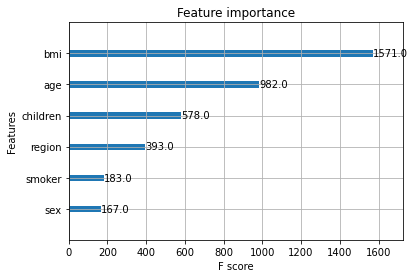

In [45]:
xgboost.plot_importance(xgb)

### 